# Week 2 - Thursday: Feature Selection vs Dimensionality Reduction + Full Comparison

**Datasets:** Titanic (seaborn, needs internet), Wine and Breast Cancer (built in)

**Goal:** understand feature selection vs dimensionality reduction, then compare Naive Bayes, Decision Tree and kNN with confusion matrices and metrics.

**Done when:** I have the results table and the confusion matrices for all three models.

---
### Quick theory
**Feature selection** keeps a **subset of the original features** (e.g. `SelectKBest`, tree feature importances). The features stay interpretable.

**Dimensionality reduction** creates **new features** that combine the originals (e.g. **PCA**). They are less interpretable but compress the data.

**PCA** finds new axes (principal components) that capture the most variance. PC1 captures the most, PC2 the next most, and so on. Data must be scaled first. `explained_variance_ratio_` tells how much variance each component keeps.

**Metrics**
- **Confusion matrix:** rows = true class, columns = predicted class. The diagonal is correct predictions.
- **Accuracy:** share of correct predictions.
- **Precision:** of the predicted positives, how many were really positive.
- **Recall:** of the real positives, how many did we find.
- **F1:** the balance of precision and recall.
- For Wine (3 classes) we use the **macro average** (the average over classes).

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine, load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score)

sns.set_theme(style="whitegrid")

## Load the three datasets

In [2]:
wine = load_wine(as_frame=True)
cancer = load_breast_cancer(as_frame=True)
titanic = sns.load_dataset("titanic")

datasets = {
    "Titanic": (titanic[["age", "fare", "pclass", "sex", "embarked"]], titanic["survived"]),
    "Wine": (wine.data, wine.target),
    "Breast Cancer": (cancer.data, cancer.target),
}

for name, (X, y) in datasets.items():
    print(f"{name}: {X.shape[0]} rows, {X.shape[1]} features")

Titanic: 891 rows, 5 features
Wine: 178 rows, 13 features
Breast Cancer: 569 rows, 30 features


## Step 1a: Feature selection on Wine with `SelectKBest`
`SelectKBest` scores each **original** feature by how strongly it is related to the class (ANOVA F-score) and keeps the top k.

In [3]:
X_wine, y_wine = wine.data, wine.target

selector = SelectKBest(score_func=f_classif, k=5).fit(X_wine, y_wine)
scores = pd.Series(selector.scores_, index=X_wine.columns).sort_values(ascending=False)

print("Top 5 original features:")
print(scores.head(5).round(1).to_string())

Top 5 original features:
flavanoids                      233.9
proline                         207.9
od280/od315_of_diluted_wines    190.0
alcohol                         135.1
color_intensity                 120.7


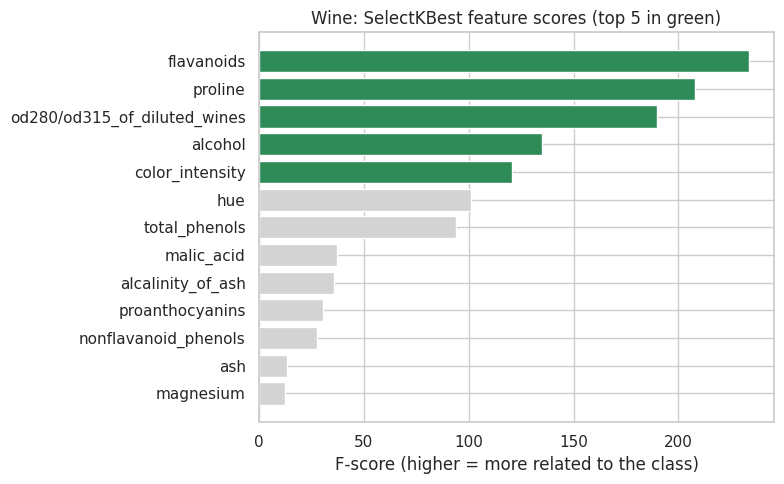

In [4]:
colors = ["seagreen" if f in scores.index[:5] else "lightgrey" for f in scores.index]
plt.figure(figsize=(8, 5))
plt.barh(scores.index[::-1], scores.values[::-1], color=colors[::-1])
plt.xlabel("F-score (higher = more related to the class)")
plt.title("Wine: SelectKBest feature scores (top 5 in green)")
plt.tight_layout()
plt.show()

**What we see:** the selected features (`flavanoids`, `proline`, ...) are **original** columns, so we can still say what they mean.

## Step 1b: Dimensionality reduction on Wine with PCA
PCA is affected by scale, so the data is scaled first. We reduce 13 features to 2 new ones and colour the points by class.

In [5]:
X_scaled = StandardScaler().fit_transform(X_wine)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
ratio = pca.explained_variance_ratio_

print(f"PC1 keeps {ratio[0]:.1%} of the variance")
print(f"PC2 keeps {ratio[1]:.1%} of the variance")
print(f"Together: {ratio.sum():.1%}")

PC1 keeps 36.2% of the variance
PC2 keeps 19.2% of the variance
Together: 55.4%


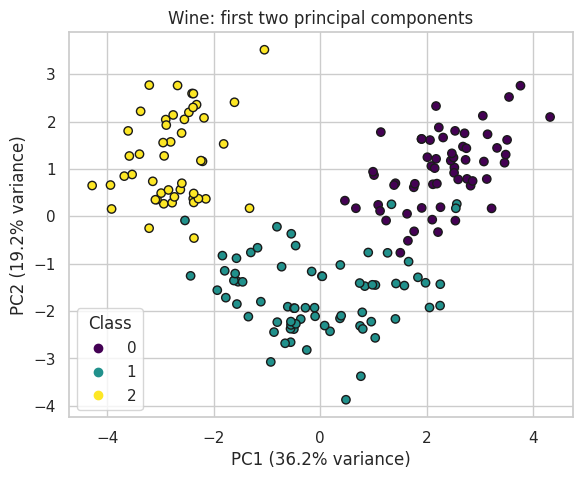

In [6]:
plt.figure(figsize=(6.5, 5))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_wine, cmap="viridis", edgecolor="k")
plt.xlabel(f"PC1 ({ratio[0]:.1%} variance)")
plt.ylabel(f"PC2 ({ratio[1]:.1%} variance)")
plt.title("Wine: first two principal components")
plt.legend(*scatter.legend_elements(), title="Class")
plt.show()

**What we see:** the three wine classes separate well in just 2 dimensions, even though PC1 and PC2 keep only about 55% of the variance. The new axes are mixtures of all 13 original features, so they are harder to interpret.

How many components do we need? The plot below shows the variance kept as we add components.

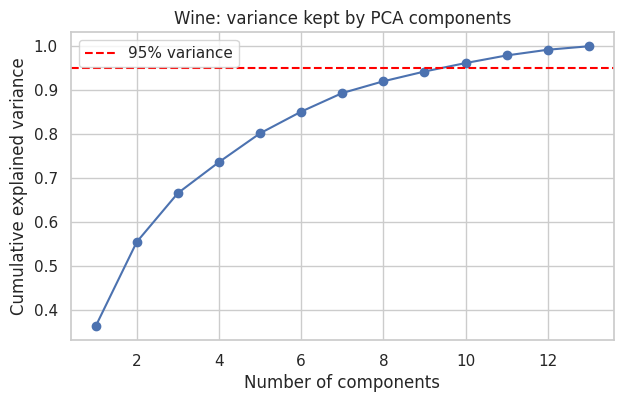

Components needed for 95% variance: 10


In [7]:
pca_full = PCA().fit(X_scaled)
cumulative = pca_full.explained_variance_ratio_.cumsum()

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cumulative) + 1), cumulative, marker="o")
plt.axhline(0.95, color="red", linestyle="--", label="95% variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("Wine: variance kept by PCA components")
plt.legend()
plt.show()

print("Components needed for 95% variance:", int((cumulative < 0.95).sum() + 1))

### Feature selection vs dimensionality reduction

| | Feature selection | Dimensionality reduction |
|---|---|---|
| What it does | Keeps a **subset of the original** features | Creates **new** features that mix the originals |
| Example | `SelectKBest` | PCA |
| Interpretable? | Yes | Less (PC1 is a mixture) |
| Wine example | Top 5: flavanoids, proline, ... | 13 features -> 2 PCs (55% variance) |

## Step 2: The checkpoint pipeline (preprocessing + 3 classifiers)
`build_preprocessor` picks the right steps from the column types: numeric columns get imputer + scaler, categorical columns get imputer + one-hot. One function, `cv_scores_for_dataset`, returns the cross-validated accuracy of all three classifiers for any dataset.

In [8]:
def build_preprocessor(X):
    numeric_cols = X.select_dtypes(include="number").columns.tolist()
    categorical_cols = [c for c in X.columns if c not in numeric_cols]
    transformers = [("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numeric_cols)]
    if categorical_cols:
        transformers.append(("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical_cols))
    return ColumnTransformer(transformers)


def get_classifiers():
    return {
        "Naive Bayes": GaussianNB(),
        "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
        "kNN": KNeighborsClassifier(n_neighbors=5),
    }


def make_pipelines(X):
    return {name: Pipeline([("preprocess", build_preprocessor(X)), ("clf", clf)])
            for name, clf in get_classifiers().items()}


def cv_scores_for_dataset(X, y):
    return {name: cross_val_score(pipe, X, y, cv=5).mean()
            for name, pipe in make_pipelines(X).items()}

In [9]:
cv_table = pd.DataFrame({name: cv_scores_for_dataset(X, y)
                         for name, (X, y) in datasets.items()}).T
cv_table.round(3)

,Naive Bayes,Decision Tree,kNN
Titanic,0.777,0.790,0.804
Wine,0.966,0.894,0.949
Breast Cancer,0.928,0.921,0.965


## Step 3: Confusion matrices (three models side by side, for each dataset)
Each model is fitted on a stratified train/test split and the predictions on the test set are stored.

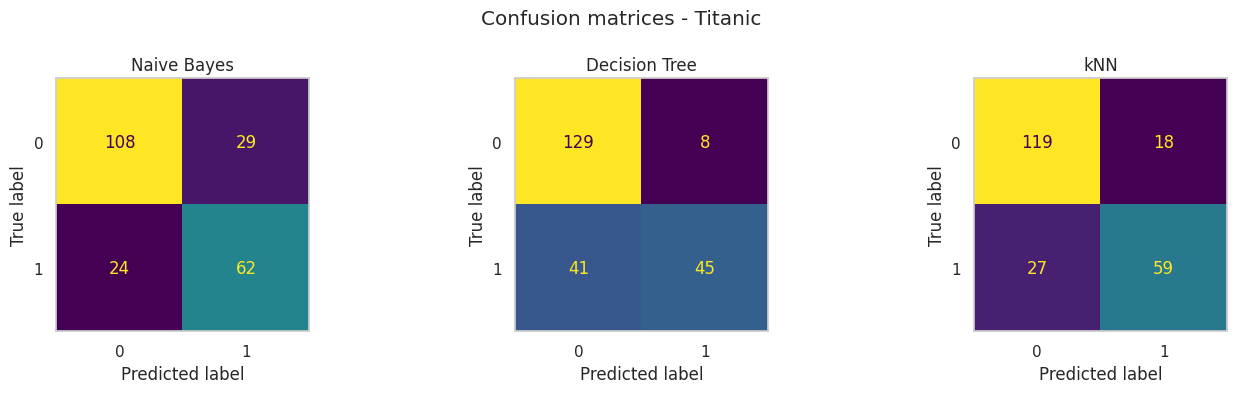

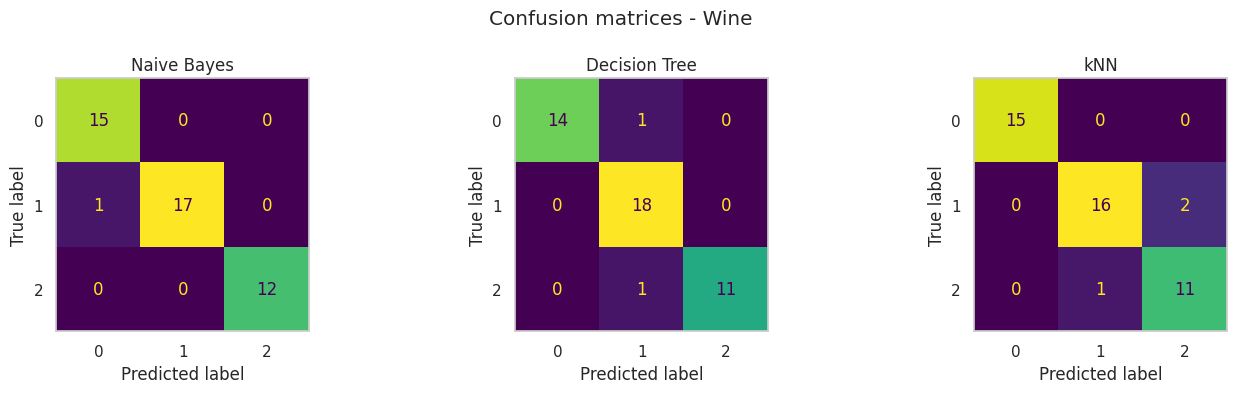

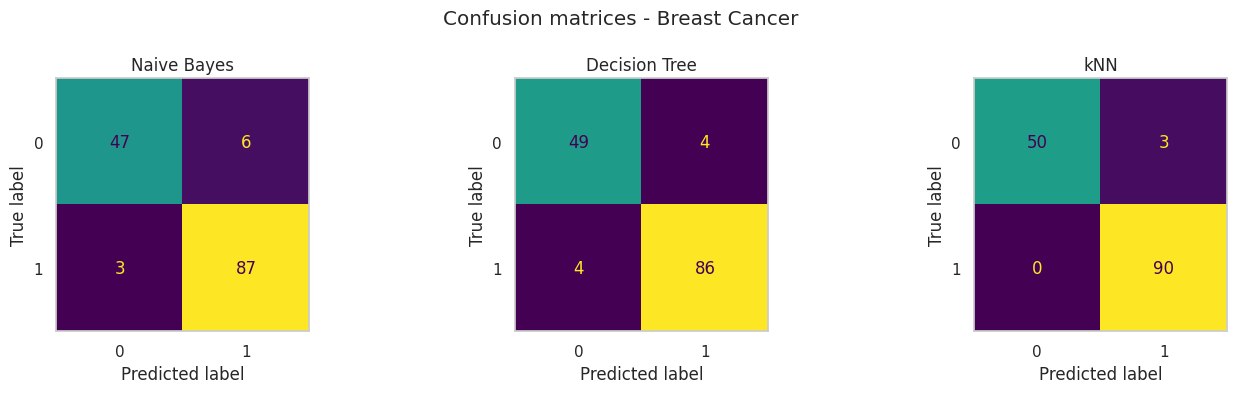

In [10]:
predictions = {}   # (dataset, model) -> (y_test, y_pred)

for ds_name, (X, y) in datasets.items():
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, stratify=y, random_state=42
    )
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, (model_name, pipe) in zip(axes, make_pipelines(X).items()):
        pipe.fit(X_train, y_train)
        y_pred = pipe.predict(X_test)
        predictions[(ds_name, model_name)] = (y_test, y_pred)

        ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, colorbar=False)
        ax.set_title(model_name)
        ax.grid(False)

    fig.suptitle(f"Confusion matrices - {ds_name}")
    plt.tight_layout()
    plt.show()

**Reading a confusion matrix:** the diagonal is correct predictions. Off-diagonal numbers are mistakes. For Titanic and Breast Cancer, the top-right and bottom-left cells show the two kinds of errors.

## Step 4: Accuracy, precision, recall and F1 in one table and one bar chart

In [11]:
rows = []
for (ds_name, model_name), (y_test, y_pred) in predictions.items():
    rows.append({
        "Dataset": ds_name,
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1": f1_score(y_test, y_pred, average="macro", zero_division=0),
    })

results = pd.DataFrame(rows).round(3)
results

,Dataset,Model,Accuracy,Precision,Recall,F1
0,Titanic,Naive Bayes,0.762,0.750,0.755,0.752
1,Titanic,Decision Tree,0.780,0.804,0.732,0.744
2,Titanic,kNN,0.798,0.791,0.777,0.782
3,Wine,Naive Bayes,0.978,0.979,0.981,0.980
4,Wine,Decision Tree,0.956,0.967,0.950,0.956
5,Wine,kNN,0.933,0.929,0.935,0.931
6,Breast Cancer,Naive Bayes,0.937,0.938,0.927,0.932
7,Breast Cancer,Decision Tree,0.944,0.940,0.940,0.940
8,Breast Cancer,kNN,0.979,0.984,0.972,0.977


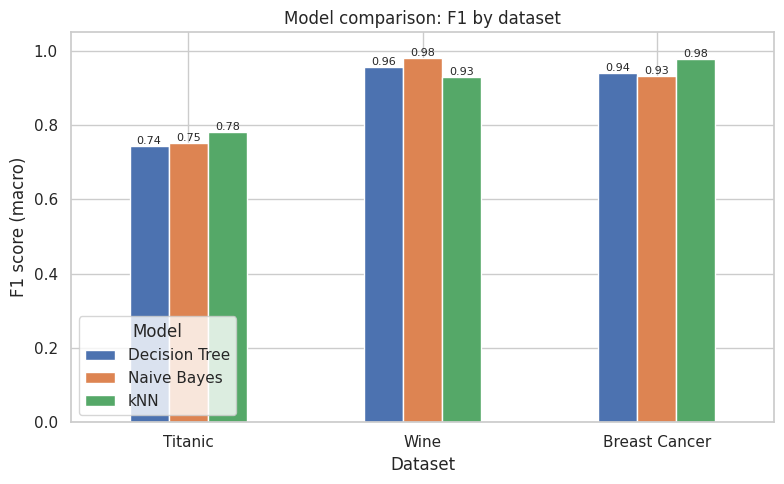

In [12]:
pivot = results.pivot(index="Dataset", columns="Model", values="F1").loc[list(datasets.keys())]
ax = pivot.plot(kind="bar", figsize=(8, 5), rot=0)
ax.set_ylabel("F1 score (macro)")
ax.set_ylim(0, 1.05)
ax.set_title("Model comparison: F1 by dataset")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8)
plt.tight_layout()
plt.show()

### Breast Cancer: recall on the malignant class
In scikit-learn's Breast Cancer data, class **0 = malignant**. Missing a malignant tumour is the worst mistake, so **recall on the malignant class** matters most here.

In [13]:
malignant_recall = {
    model_name: recall_score(y_test, y_pred, pos_label=0)
    for (ds_name, model_name), (y_test, y_pred) in predictions.items()
    if ds_name == "Breast Cancer"
}
pd.Series(malignant_recall, name="Recall (malignant)").round(3)

Naive Bayes      0.887
Decision Tree    0.925
kNN              0.943
Name: Recall (malignant), dtype: float64

In [14]:
results.to_csv("results_table.csv", index=False)
print("Saved results_table.csv in the current folder")

Saved results_table.csv in the current folder


---
## Notes (Thursday)
- **Feature selection:** keeps a subset of the original features (example: `SelectKBest` kept flavanoids, proline, ... on Wine). Interpretable.
- **Dimensionality reduction:** builds new features from mixtures of the originals (example: PCA turned Wine's 13 features into 2 components keeping about 55% of the variance). Compresses the data but is less interpretable.

### First impressions: which model won where
- **Wine:** Naive Bayes did best (highest CV accuracy). The classes are well separated and the features are roughly bell-shaped, which suits Gaussian Naive Bayes.
- **Breast Cancer:** scaled kNN did best, including the highest malignant recall. Once the features are scaled, nearby points have the same class very consistently.
- **Titanic:** the three models are close (all around 0.78 to 0.80), with kNN slightly ahead. The data is noisy, so no model is far better than the others.
- The Decision Tree is the least stable in cross-validation, which matches its tendency to overfit.

Friday: write the full performance comparison summary and push everything to GitHub.